# 🔍 Lesson 08 · Convolutional Neural Networks

*“A CNN looks at a picture the way you read a page: small window, slide along, same eyes everywhere.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~120 min | 🟡 Intermediate | Day 6–7 | Lessons 05–07 (especially the shift-robustness test!) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain the three CNN ideas: **local connectivity, weight sharing, hierarchy of features**
- Compute a **2-D convolution by hand** and implement it in NumPy
- Use **filters** as edge/texture detectors and see what a learned filter looks like
- Calculate **output sizes** (kernel, stride, padding), **parameter counts** and **receptive fields**
- Understand **pooling** and why it gives tolerance to small shifts
- Build, train and inspect a CNN in PyTorch and show it beats an ANN under shifts

## 🗺 Roadmap
1. Why ANNs struggle with images
2. Convolution by hand
3. Filters = feature detectors
4. Size formulas, stride & padding
5. Channels & parameter counting
6. Pooling
7. Receptive fields
8. A CNN in PyTorch
9. Looking inside
10. Layout gotchas & history
11. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 😩 1. Why fully-connected networks struggle with images

Three problems with feeding pixels into an ANN:

1. **Parameter explosion.** A modest 48×48 colour leaf photo has 6,912 inputs. One hidden layer of 512 neurons already needs **3.5 million** weights, and real photos are 1000× larger.
2. **No notion of location-independence.** In Lesson 07 shifting a digit by 3 pixels crushed accuracy: the ANN had to learn "a 7 at *this* spot", "a 7 at *that* spot" separately.
3. **It ignores spatial structure.** Neighbouring pixels are strongly related (edges, textures) but an ANN treats pixel (0,0) and pixel (27,27) as equally 'related'.

**CNN's three big ideas**: each solves one problem:

| Idea | Meaning | Fixes |
|:--|:--|:--|
| **Local connectivity** | Each neuron looks at only a small patch (e.g. 3×3) | Parameter explosion, ignoring structure |
| **Weight sharing** | The *same* small filter slides over every position | Location-independence ("a vertical edge is a vertical edge anywhere") |
| **Hierarchy** | Stack layers: edges → corners/textures → parts → objects | Learning rich concepts from simple pieces |

> 🌽 **Analogy.** A scout walking a maize field with a checklist ("yellow streaks? brown spots?"). The checklist is the *filter*; walking every row is *sliding*; the same checklist works in every part of the field: that's weight sharing.

---
## 🧮 2. Convolution by hand

A **filter (kernel)** is a small grid of weights. To convolve: place it over a patch of the image, multiply element-wise, **sum** → one output number; slide one step; repeat.

*(Strictly, deep-learning "convolution" is **cross-correlation**: no kernel flip. Everyone says "convolution" anyway.)*

**Worked example.** One 3×3 patch and a Sobel vertical-edge kernel:

$$\text{patch}=\begin{bmatrix}1&2&0\\0&1&3\\2&1&0\end{bmatrix},\quad
K=\begin{bmatrix}1&0&-1\\2&0&-2\\1&0&-1\end{bmatrix}$$

Row 1: $1\cdot1+2\cdot0+0\cdot(-1)=1$ · Row 2: $0\cdot2+1\cdot0+3\cdot(-2)=-6$ · Row 3: $2\cdot1+1\cdot0+0\cdot(-1)=2$ → **output $=1-6+2=-3$**.

The kernel computes "left side minus right side": it responds strongly where brightness *changes horizontally*: a vertical edge. Now in code:

In [2]:
def conv2d_naive(x, k, stride=1, padding=0):
    """Single-channel 2-D cross-correlation with loops: slow but crystal clear."""
    if padding:
        x = np.pad(x, padding)                       # zero-pad all four sides
    H, W = x.shape; kh, kw = k.shape
    oh, ow = (H - kh) // stride + 1, (W - kw) // stride + 1
    out = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            patch = x[i * stride:i * stride + kh, j * stride:j * stride + kw]
            out[i, j] = np.sum(patch * k)            # multiply element-wise, then add up
    return out

patch = np.array([[1, 2, 0], [0, 1, 3], [2, 1, 0]], float)
sobel_v = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
print("hand example →", conv2d_naive(patch, sobel_v))                  # a 1×1 output: [[-3.]]

from scipy.signal import correlate2d
rng = np.random.default_rng(0); img = rng.normal(size=(8, 8)); ker = rng.normal(size=(3, 3))
print("matches scipy:", np.allclose(conv2d_naive(img, ker), correlate2d(img, ker, mode="valid")))

hand example → [[-3.]]


matches scipy: True


---
## 🎨 3. Filters are feature detectors

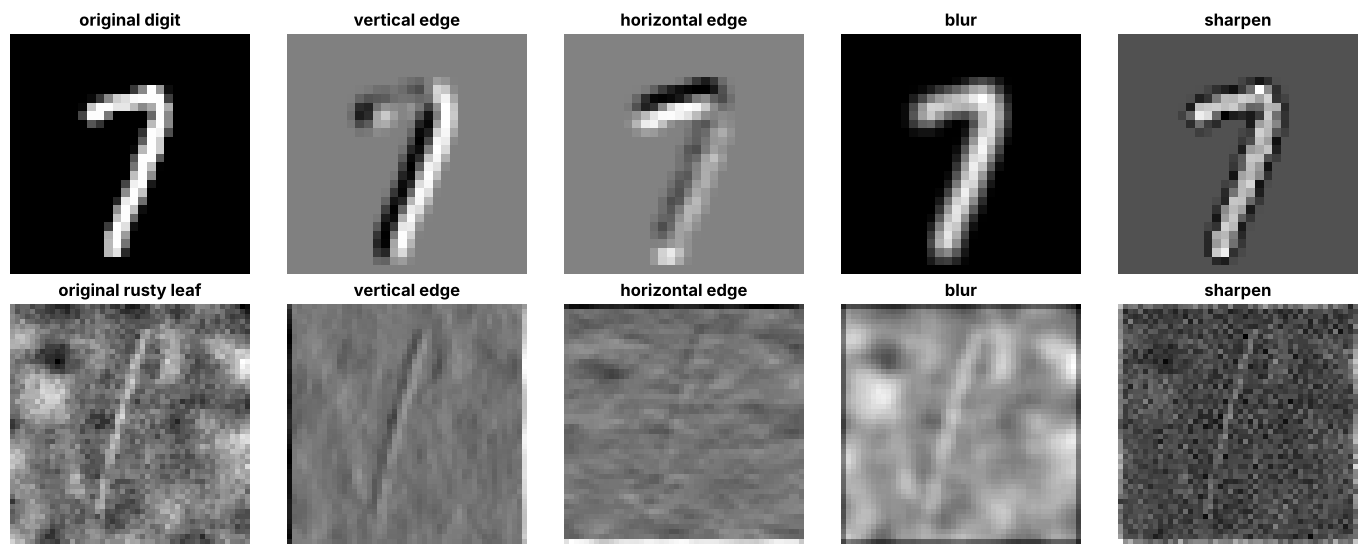

In [3]:
x_tr, y_tr, x_te, y_te = dl.load_mnist(n_train=10000, n_test=2000)
leaves = dl.load_leaves()
digit = x_te[np.where(y_te == 7)[0][0]]
leaf = leaves["x_train"][np.where(leaves["y_train"] == 3)[0][0]].mean(-1)         # a rusty leaf in grayscale

kernels = {
    "vertical edge":   np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float),
    "horizontal edge": np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], float),
    "blur":            np.ones((3, 3)) / 9,
    "sharpen":         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6))
for row, (name, img) in enumerate([("digit", digit), ("rusty leaf", leaf)]):
    axes[row, 0].imshow(img, cmap="gray"); axes[row, 0].set_title(f"original {name}")
    for col, (kname, k) in enumerate(kernels.items(), 1):
        axes[row, col].imshow(conv2d_naive(img, k, padding=1), cmap="gray"); axes[row, col].set_title(kname)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

> 💡 **Big idea**: In classical computer vision, humans *designed* kernels like these. In a CNN, **the kernel values are weights that gradient descent learns**: so the network invents whatever detectors help the task: edges first, then textures, then parts like 'brown lesion' or 'curved stroke'.

---
## 📐 4. Output size, stride & padding

For input width $n$, kernel size $k$, padding $p$, stride $s$:

$$\boxed{\;n_{out}=\Big\lfloor \frac{n+2p-k}{s}\Big\rfloor+1\;}$$

| Setting | Example ($n=28$) | Output | Effect |
|:--|:--|:-:|:--|
| No padding ("valid"), $s=1$, $k=5$ | $\lfloor(28-5)/1\rfloor+1$ | 24 | Image **shrinks** by $k-1$ |
| Padding $p=2$, $s=1$, $k=5$ ("same") | $\lfloor(28+4-5)/1\rfloor+1$ | 28 | Size **preserved** ($p=(k-1)/2$) |
| $s=2$, $k=3$, $p=1$ | $\lfloor(28+2-3)/2\rfloor+1$ | 14 | **Halves** the image |

* **Padding** keeps borders from being ignored and preserves size.
* **Stride** > 1 skips positions: cheaper, downsamples.

In [4]:
def conv_out(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1
for (k, s, p) in [(5, 1, 0), (5, 1, 2), (3, 2, 1), (7, 2, 3)]:
    print(f"28×28, kernel {k}, stride {s}, padding {p}  →  {conv_out(28, k, s, p)}×{conv_out(28, k, s, p)}")

28×28, kernel 5, stride 1, padding 0  →  24×24
28×28, kernel 5, stride 1, padding 2  →  28×28
28×28, kernel 3, stride 2, padding 1  →  14×14
28×28, kernel 7, stride 2, padding 3  →  14×14


---
## 📚 5. Channels & parameter counting

Real images have **channels** (1 for grayscale, 3 for RGB) and a conv layer produces **many** feature maps (one per filter). A layer with $C_{in}$ input channels, $C_{out}$ filters of size $k\times k$:

* each filter has shape $(C_{in},k,k)$: it looks at *all* input channels at once,
* **parameters $=(k\cdot k\cdot C_{in}+1)\cdot C_{out}$** (the +1 is each filter's bias).

**Compare** on a 28×28 image: an ANN layer to 784 hidden units needs $784\times784=614{,}656$ weights. A conv layer with 16 filters of 5×5 on 1 channel needs just $(25+1)\cdot16=\mathbf{416}$: and it applies at **every** position. *That's weight sharing.*

In [5]:
conv_params = lambda c_in, c_out, k: (k * k * c_in + 1) * c_out
print("conv 1→16, k=5      :", conv_params(1, 16, 5))
print("conv 16→32, k=5     :", conv_params(16, 32, 5))
print("conv 3→32, k=3 (RGB):", conv_params(3, 32, 3))
print("dense 784→784       :", 784 * 784 + 784)
layer = nn.Conv2d(3, 32, kernel_size=3)
print("PyTorch agrees:", dl.count_params(layer), "| weight shape:", tuple(layer.weight.shape), "= (C_out, C_in, k, k)")

conv 1→16, k=5      : 416
conv 16→32, k=5     : 12832
conv 3→32, k=3 (RGB): 896
dense 784→784       : 615440
PyTorch agrees: 896 | weight shape: (32, 3, 3, 3) = (C_out, C_in, k, k)


---
## 🏊 6. Pooling

**Max pooling** slides a window (usually 2×2, stride 2) and keeps only the **maximum** in each window. It halves the height and width (4× fewer values), has **no parameters**, and: importantly: makes the representation **tolerant to small shifts**: if the strongest response moves one pixel *inside* the window, the output doesn't change.

In [6]:
fmap = np.zeros((4, 4)); fmap[1, 1] = 9                        # a strong feature detected at (1,1)
shifted = np.zeros((4, 4)); shifted[0, 1] = 9                  # the same feature shifted up one pixel

def maxpool2x2(a):
    H, W = a.shape
    return a.reshape(H // 2, 2, W // 2, 2).max(axis=(1, 3))     # a neat reshape trick

print("pooled original:\n", maxpool2x2(fmap)); print("pooled shifted: \n", maxpool2x2(shifted))
print("identical?", np.array_equal(maxpool2x2(fmap), maxpool2x2(shifted)))

pooled original:
 [[9. 0.]
 [0. 0.]]
pooled shifted: 
 [[9. 0.]
 [0. 0.]]
identical? True


> 📝 **Note**: Pooling gives *small* shift tolerance, not full invariance. Stacking conv+pool layers grows the tolerance (and the context each neuron sees). Modern nets sometimes replace pooling with stride-2 convolutions: same idea.

---
## 🔭 7. Receptive fields

A neuron's **receptive field** is the patch of the *original image* that can influence it. One 3×3 conv sees 3×3; stack two and a deep neuron sees 5×5; add a pool and the growth accelerates. Deeper neurons see more context: that's how a late-layer neuron can recognise 'a whole leaf with streaks' while an early one only sees edges.

In [7]:
def receptive_field(layers):
    """layers: list of (kernel, stride). Returns the receptive field after each layer."""
    rf, jump, out = 1, 1, []
    for k, s in layers:
        rf += (k - 1) * jump        # each new layer adds (k-1) steps of the CURRENT spacing
        jump *= s                   # striding spreads later neurons further apart
        out.append(rf)
    return out
net = [(5, 1), (2, 2), (5, 1), (2, 2)]           # conv5 → pool2 → conv5 → pool2  (our MNIST CNN)
print("receptive field after each layer:", receptive_field(net), " ← final neurons see 16×16 of the 28×28 image")
print("ten stacked 3×3 convs:", receptive_field([(3, 1)] * 10)[-1], "pixels wide")

receptive field after each layer: [5, 6, 14, 16]  ← final neurons see 16×16 of the 28×28 image
ten stacked 3×3 convs: 21 pixels wide


---
## 🏗 8. A CNN in PyTorch

Architecture (a mini **LeNet**, inspired by LeCun's 1998 network):

```
Input (1×28×28)
 → Conv 5×5, 8 filters, pad 2 → ReLU → MaxPool 2×2        (8×14×14)
 → Conv 5×5, 16 filters, pad 2 → ReLU → MaxPool 2×2       (16×7×7)
 → Flatten (784) → Linear 64 → ReLU → Linear 10           (logits)
```
**The CNN pattern:** `[Conv → ReLU → Pool] × few → Flatten → Dense classifier`. Convolutions *extract features*; the dense layers *decide*.
First a little tool that **traces shapes** layer by layer (use it constantly!):

In [8]:
def trace_shapes(model, input_shape):
    x = torch.zeros(1, *input_shape)
    print(f"{'input':28s} {tuple(x.shape)}")
    for layer in model:
        x = layer(x)
        print(f"{layer.__class__.__name__:28s} {tuple(x.shape)}")

cnn = nn.Sequential(
    nn.Conv2d(1, 8, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(8, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(16 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))
trace_shapes(cnn, (1, 28, 28))
print("CNN parameters:", f"{dl.count_params(cnn):,}")

input                        (1, 1, 28, 28)


Conv2d                       (1, 8, 28, 28)
ReLU                         (1, 8, 28, 28)
MaxPool2d                    (1, 8, 14, 14)
Conv2d                       (1, 16, 14, 14)
ReLU                         (1, 16, 14, 14)
MaxPool2d                    (1, 16, 7, 7)
Flatten                      (1, 784)
Linear                       (1, 64)
ReLU                         (1, 64)
Linear                       (1, 10)
CNN parameters: 54,314


Now a **fair fight**: train this CNN and an ANN with a *similar* parameter budget on the same 10,000 images, and run the shift test from Lesson 07.

In [9]:
mu, sd = x_tr.mean(), x_tr.std()
def to_t(a, add_channel):                                  # CNN needs (N,1,28,28); the ANN's Flatten accepts either
    t = torch.tensor((a - mu) / sd, dtype=torch.float32)
    return t[:, None] if add_channel else t
Xtr, Xte = to_t(x_tr, True), to_t(x_te, True)
Ytr, Yte = torch.tensor(y_tr), torch.tensor(y_te)
train_dl = DataLoader(TensorDataset(Xtr, Ytr), batch_size=64, shuffle=True)
test_dl = DataLoader(TensorDataset(Xte, Yte), batch_size=500)

dl.set_seed(0)
ann = nn.Sequential(nn.Flatten(), nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 10))      # ~51k params
print("ANN params:", f"{dl.count_params(ann):,}", "| CNN params:", f"{dl.count_params(cnn):,}")
h_ann = dl.fit(ann, train_dl, test_dl, nn.CrossEntropyLoss(), torch.optim.Adam(ann.parameters(), 1e-3), epochs=5, device=cpu, verbose=False)
h_cnn = dl.fit(cnn, train_dl, test_dl, nn.CrossEntropyLoss(), torch.optim.Adam(cnn.parameters(), 1e-3), epochs=5, device=cpu, verbose=False)
print(f"ANN accuracy {h_ann['val_acc'][-1]:.2%}   ({h_ann['seconds']:.0f}s)")
print(f"CNN accuracy {h_cnn['val_acc'][-1]:.2%}   ({h_cnn['seconds']:.0f}s)")

ANN params: 50,890 | CNN params: 54,314


ANN accuracy 94.45%   (1s)
CNN accuracy 97.75%   (9s)


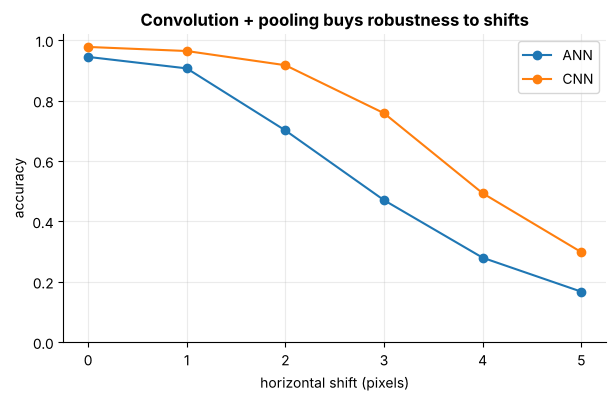

{'ANN': [0.94, 0.91, 0.7, 0.47, 0.28, 0.17], 'CNN': [0.98, 0.96, 0.92, 0.76, 0.49, 0.3]}


In [10]:
def shift_images(x, dx=0, dy=0):
    out = np.zeros_like(x); H, W = x.shape[1:]
    sy, ty = slice(max(0, -dy), H - max(0, dy)), slice(max(0, dy), H - max(0, -dy))
    sx, tx = slice(max(0, -dx), W - max(0, dx)), slice(max(0, dx), W - max(0, -dx))
    out[:, ty, tx] = x[:, sy, sx]
    return out

shifts = [0, 1, 2, 3, 4, 5]
acc = {"ANN": [], "CNN": []}
for d in shifts:
    xs = to_t(shift_images(x_te, dx=d), True)
    for name, m in [("ANN", ann), ("CNN", cnn)]:
        acc[name].append((dl.predict_proba(m, xs, device=cpu).argmax(1).numpy() == y_te).mean())
for name, a in acc.items(): plt.plot(shifts, a, "o-", label=name)
plt.xlabel("horizontal shift (pixels)"); plt.ylabel("accuracy"); plt.ylim(0, 1.02); plt.legend(); plt.title("Convolution + pooling buys robustness to shifts"); plt.show()
print({k: np.round(v, 2).tolist() for k, v in acc.items()})

> 💡 **Big idea**: Same data, *fewer* parameters, higher accuracy, and noticeably better behaviour under shifts (though not immune; a 5-pixel shift still hurts; augmentation helps further). **The architecture encodes a useful assumption** (patterns are local and can appear anywhere): this is called an **inductive bias**, and choosing good ones is a central skill in deep learning.

---
## 🔬 9. Looking inside the network

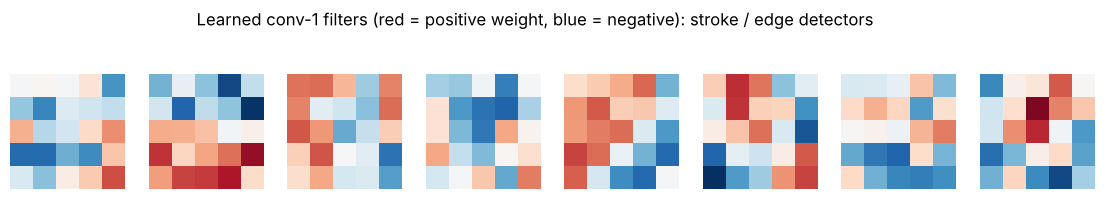

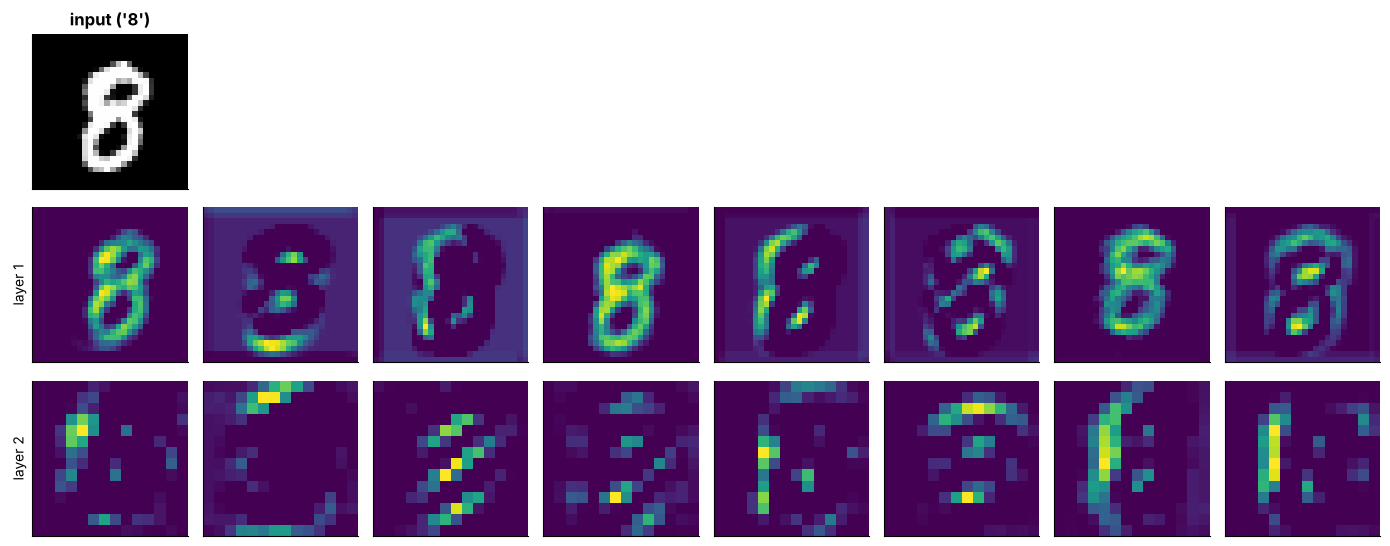

In [11]:
# 1) The learned first-layer filters (8 filters of 5×5)
w1 = cnn[0].weight.detach().numpy()[:, 0]                       # (8, 5, 5)
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for a, f in zip(axes, w1): a.imshow(f, cmap="RdBu", vmin=-abs(w1).max(), vmax=abs(w1).max()); a.axis("off")
fig.suptitle("Learned conv-1 filters (red = positive weight, blue = negative): stroke / edge detectors", y=1.05); plt.show()

# 2) Feature maps for one input after each stage
x = Xte[:1]
with torch.no_grad():
    f1 = cnn[:2](x)[0]                                           # after conv1 + ReLU : (8, 28, 28)
    f2 = cnn[:5](x)[0]                                           # after conv2 + ReLU : (16, 14, 14)
fig, axes = plt.subplots(3, 8, figsize=(14, 5.6))
axes[0, 0].imshow(x[0, 0], cmap="gray"); axes[0, 0].set_title(f"input ('{y_te[0]}')")
for i in range(8):
    axes[1, i].imshow(f1[i], cmap="viridis"); axes[2, i].imshow(f2[i], cmap="viridis")
axes[1, 0].set_ylabel("layer 1"); axes[2, 0].set_ylabel("layer 2")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
for a in axes[0, 1:]: a.axis("off")
plt.tight_layout(); plt.show()

Each map shows *where* a particular feature fired. Layer 1 maps look like the digit filtered by edge/stroke detectors; layer 2 maps are coarser and more abstract: combinations of strokes (curves, junctions).

---
## 🧳 10. Layout gotchas & a little history

> ⚠️ **Watch out**: **Channel order.** PyTorch wants **(N, C, H, W)**. NumPy/PIL/matplotlib images are **(H, W, C)**. Our leaf dataset is channels-last, so you'll do `x.permute(0, 3, 1, 2)` in Lesson 10. Forgetting this gives bizarre shape errors or (worse) silently wrong results when sizes happen to match.

| Year | Network | Why it mattered |
|:--|:--|:--|
| 1998 | **LeNet-5** (LeCun) | First practical CNN: digits, cheques, ZIP codes |
| 2012 | **AlexNet** | Won ImageNet by a huge margin using GPUs + ReLU + dropout; ignited the deep-learning boom |
| 2014 | **VGG**, **GoogLeNet** | Depth with small 3×3 filters; "inception" modules |
| 2015 | **ResNet** | *Skip connections* let you train 100+ layers (fixes vanishing gradients) |
| 2019 | **EfficientNet** | Scale depth, width and resolution together |
| 2020– | **Vision Transformers** | Attention instead of convolution (Lesson 13) |

You rarely train these from scratch: **transfer learning** starts from a network pretrained on ImageNet and fine-tunes it on your data (Lesson 10).

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 8.1: Output size calculator  &nbsp; `⭐`

Write `conv_out(n, k, s=1, p=0)` returning the output width/height of a convolution or pooling layer. Then use it to compute the final spatial size of: 64×64 input → conv(k=3,s=1,p=1) → pool(k=2,s=2) → conv(k=3,s=1,p=0) → pool(k=2,s=2), storing it in `final_size`.

<details><summary>💡 Hint 1</summary>

The formula: `(n + 2*p - k) // s + 1`.

</details>

<details><summary>💡 Hint 2</summary>

Apply it four times in a row, feeding each output into the next call.

</details>


In [ ]:
def conv_out(n, k, s=1, p=0):
    pass

final_size = None

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("conv_out(28,5,1,0) = 24", conv_out(28, 5, 1, 0) == 24)
dl.check("conv_out(28,5,1,2) = 28 ('same' padding)", conv_out(28, 5, 1, 2) == 28)
dl.check("conv_out(28,3,2,1) = 14", conv_out(28, 3, 2, 1) == 14)
dl.check("final_size = 15", final_size == 15, "trace each step on paper")

---
### 🧩 Problem 8.2: Count conv parameters  &nbsp; `⭐`

Write `conv_params(c_in, c_out, k, bias=True)`. Then compute `total` = parameters of: Conv(3→16,k=3) + Conv(16→32,k=3) + Conv(32→64,k=3).

<details><summary>💡 Hint 1</summary>

Each filter has `k*k*c_in` weights, and there are `c_out` filters.

</details>

<details><summary>💡 Hint 2</summary>

Add `c_out` biases if `bias=True`.

</details>


In [ ]:
def conv_params(c_in, c_out, k, bias=True):
    pass

total = None

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("conv_params(1,16,5) = 416", conv_params(1, 16, 5) == 416)
dl.check("without bias: 400", conv_params(1, 16, 5, bias=False) == 400)
dl.check("total = 448 + 4640 + 18496 = 23,584", total == 23584)

---
### 🧩 Problem 8.3: Implement convolution (with stride & padding)  &nbsp; `⭐⭐⭐`

Write `conv2d(x, k, stride=1, padding=0)` for a 2-D single-channel image `x` and kernel `k` (cross-correlation, zero padding). The self-check compares with PyTorch's `F.conv2d`.

<details><summary>💡 Hint 1</summary>

`np.pad(x, padding)` pads all sides with zeros.

</details>

<details><summary>💡 Hint 2</summary>

Output size: `(H - kh)//stride + 1` (after padding).

</details>

<details><summary>💡 Hint 3</summary>

Loop over output positions; the patch is `x[i*stride : i*stride+kh, j*stride : j*stride+kw]`.

</details>


In [ ]:
def conv2d(x, k, stride=1, padding=0):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
import torch, torch.nn.functional as F
rng = np.random.default_rng(1); x = rng.normal(size=(9, 9)); k = rng.normal(size=(3, 3))
for s, p in [(1, 0), (1, 1), (2, 1)]:
    mine = conv2d(x, k, s, p)
    ref = F.conv2d(torch.tensor(x)[None, None], torch.tensor(k)[None, None], stride=s, padding=p)[0, 0].numpy()
    dl.check(f"stride={s}, padding={p}", mine is not None and mine.shape == ref.shape and np.allclose(mine, ref))

---
### 🧩 Problem 8.4: Max pooling for any window size  &nbsp; `⭐⭐`

Write `max_pool(x, size)` (stride = size) for a 2-D array whose sides are divisible by `size`. Use the reshape trick: `x.reshape(H//size, size, W//size, size).max(axis=(1, 3))`.

<details><summary>💡 Hint 1</summary>

Reshape so each window becomes its own pair of axes, then take the max over those two axes.

</details>

<details><summary>💡 Hint 2</summary>

The result has shape `(H//size, W//size)`.

</details>


In [ ]:
def max_pool(x, size=2):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = np.arange(16, dtype=float).reshape(4, 4)
dl.check("2×2 pooling gives [[5,7],[13,15]]", max_pool(x, 2) is not None and np.array_equal(max_pool(x, 2), [[5, 7], [13, 15]]))
dl.check("4×4 pooling gives one number: 15", max_pool(x, 4) is not None and np.array_equal(max_pool(x, 4), [[15]]))

---
### 🧩 Problem 8.5: Predict the flatten size  &nbsp; `⭐⭐`

Write `flat_features(input_shape, layers)` where `input_shape=(C,H,W)` and `layers` is a list like
`[("conv", c_out, k, s, p), ("pool", k)]` (pool stride = k). Return the number of features after flattening.
This is exactly the number you must put in the first `nn.Linear` after `nn.Flatten()`. Verify on the leaf-classifier CNN below.

<details><summary>💡 Hint 1</summary>

Track `(C, H, W)`. A conv sets `C = c_out` and updates `H, W` by the size formula; a pool keeps `C` and divides `H, W` by `k` (floor).

</details>

<details><summary>💡 Hint 2</summary>

Return `C * H * W`.

</details>


In [ ]:
def flat_features(input_shape, layers):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
mnist = [("conv", 8, 5, 1, 2), ("pool", 2), ("conv", 16, 5, 1, 2), ("pool", 2)]
dl.check("MNIST CNN flattens to 784", flat_features((1, 28, 28), mnist) == 784)
leaf = [("conv", 16, 3, 1, 1), ("pool", 2), ("conv", 32, 3, 1, 1), ("pool", 2), ("conv", 64, 3, 1, 1), ("pool", 2)]
dl.check("leaf CNN (48×48 RGB) flattens to 64·6·6 = 2304", flat_features((3, 48, 48), leaf) == 2304)

---
## 🏁 Key takeaways
- ✅ CNNs exploit **local patterns** (small kernels), **weight sharing** (same filter everywhere) and **hierarchy** (edges → parts → objects).
- ✅ Convolution = slide a kernel, multiply & sum. Learned kernels become feature detectors.
- ✅ **`n_out = ⌊(n + 2p − k)/s⌋ + 1`**; conv params = **`(k·k·C_in + 1)·C_out`**; pooling has no parameters.
- ✅ **Max pooling** halves the map and gives small-shift tolerance; **receptive fields** grow with depth.
- ✅ Pattern: `[Conv→ReLU→Pool]×n → Flatten → Linear`. Always **trace shapes**. PyTorch layout is **(N, C, H, W)**.
- ✅ A CNN beat a same-size ANN and was noticeably more shift-robust: the right **inductive bias** beats brute force.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why do CNNs need far fewer parameters than ANNs on images?

<details><summary>Answer</summary>

Local connectivity (each neuron sees a small patch) and weight sharing (one small filter reused at every position), instead of a separate weight for every pixel pair.

</details>

**Q2.** A 3×3 convolution with padding 1 and stride 1 is applied to a 32×32 image. Output size?

<details><summary>Answer</summary>

(32 + 2 − 3)/1 + 1 = **32**: 'same' padding.

</details>

**Q3.** What does max pooling throw away, and why is that acceptable?

<details><summary>Answer</summary>

Exact position of a feature within each window (and the non-maximum values). Acceptable because *whether* a feature is present matters more than its exact pixel location.

</details>

**Q4.** How many parameters does `nn.Conv2d(3, 64, kernel_size=7)` have?

<details><summary>Answer</summary>

(7·7·3 + 1)·64 = 148·64 = **9,472**.

</details>

---
## 📚 Go deeper (optional)
- Stanford CS231n: *Convolutional Neural Networks for Visual Recognition* notes (cs231n.github.io)
- Dumoulin & Visin (2016): *A guide to convolution arithmetic for deep learning* (animated)
- Zeiler & Fergus (2014): *Visualizing and Understanding Convolutional Networks*
- 3Blue1Brown: *But what is a convolution?*

---
⬅️ Previous: [07 · Project 1 · Handwritten Digit Recognition](07_project1_handwritten_digits.ipynb) &nbsp;|&nbsp; Next: [09 · Project 2 · Image Classification](09_project2_image_classification.ipynb) ➡️